In [10]:
from datasets import load_dataset
import polars as pl
from matplotlib import pyplot as plt

In [34]:
model_ds_map = {
    "qwen3_8B": "unlearning-cleanslate/eval_results",
    "qwen3_coder_next_80B_fp8": "unlearning-cleanslate/generated_songs_qwen3_coder_next_fp8_eval",
    # "qwen3_next_80b_a3b_instruct": "unlearning-cleanslate/generated_songs_qwen3_next_80b_a3b_instruct_eval",
}


In [23]:
import numpy as np  # Needed for log transform
def analyze_model(model: str):

    ds_name = model_ds_map[model]
    ds = load_dataset(ds_name)
    df = ds["train"].to_polars()

    percentiles = [0.25, 0.50, 0.75]  # Only need 25, 50, 75 for confidence band plots

    agg_exprs = []
    for p in percentiles:
        pct_label = int(p * 100)
        agg_exprs.append(pl.col("extraction_prob").quantile(p).alias(f"extraction_prob_p{pct_label}"))
        agg_exprs.append(pl.col("rougel").quantile(p).alias(f"rougel_p{pct_label}"))
        agg_exprs.append(pl.col("bleu1").quantile(p).alias(f"bleu1_p{pct_label}"))
        agg_exprs.append(pl.col("bleu2").quantile(p).alias(f"bleu2_p{pct_label}"))

    grouped_df = (
        df.group_by(["prompt_template", "seed_mode"])
        .agg(agg_exprs)
        .sort(["seed_mode", "prompt_template"])
    )

    seed_modes = grouped_df["seed_mode"].unique().sort().to_list()
    n_modes = len(seed_modes)

    # --- Plot 1: -log Extraction Probability (Median ± [25,75] Percentile Band) ---
    fig1, axes1 = plt.subplots(1, n_modes, figsize=(6 * n_modes, 5), sharey=True, squeeze=False)
    fig1.suptitle(f"-log(Extraction Probability) by Template & Seed Mode — {model}", fontsize=14)

    for i, mode in enumerate(seed_modes):
        ax = axes1[0, i]
        sub = grouped_df.filter(pl.col("seed_mode") == mode).sort("prompt_template")
        x = np.arange(len(sub))
        labels = sub["prompt_template"].to_list()

        # Use 25th, 50th, 75th percentiles
        p25 = np.clip(sub["extraction_prob_p25"].to_numpy(), 1e-12, None)
        p50 = np.clip(sub["extraction_prob_p50"].to_numpy(), 1e-12, None)
        p75 = np.clip(sub["extraction_prob_p75"].to_numpy(), 1e-12, None)
        neglog_p25 = -np.log(p25)
        neglog_p50 = -np.log(p50)
        neglog_p75 = -np.log(p75)

        ax.plot(x, neglog_p50, marker="o", label="median")
        ax.fill_between(x, neglog_p25, neglog_p75, color="C0", alpha=0.25, label="25–75% band")

        ax.set_title(f"seed_mode = {mode}")
        ax.set_xticks(list(x))
        ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
        ax.set_ylabel("-log(Extraction Probability)")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    fig1.tight_layout()
    plt.show()

    # --- Plot 2: ROUGE-L (Median ± [25,75] Percentile Band) ---
    fig2, axes2 = plt.subplots(1, n_modes, figsize=(6 * n_modes, 5), sharey=True, squeeze=False)
    fig2.suptitle(f"ROUGE-L by Template & Seed Mode — {model}", fontsize=14)

    for i, mode in enumerate(seed_modes):
        ax = axes2[0, i]
        sub = grouped_df.filter(pl.col("seed_mode") == mode).sort("prompt_template")
        x = np.arange(len(sub))
        labels = sub["prompt_template"].to_list()

        rouge_p25 = sub["rougel_p25"].to_numpy()
        rouge_p50 = sub["rougel_p50"].to_numpy()
        rouge_p75 = sub["rougel_p75"].to_numpy()

        ax.plot(x, rouge_p50, marker="o", label="median")
        ax.fill_between(x, rouge_p25, rouge_p75, color="C1", alpha=0.25, label="25–75% band")

        ax.set_title(f"seed_mode = {mode}")
        ax.set_xticks(list(x))
        ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
        ax.set_ylabel("ROUGE-L Score")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    fig2.tight_layout()
    plt.show()

    # --- Plot 3: BLEU-1 (Median ± [25,75] Percentile Band) ---
    fig3, axes3 = plt.subplots(1, n_modes, figsize=(6 * n_modes, 5), sharey=True, squeeze=False)
    fig3.suptitle(f"BLEU-1 by Template & Seed Mode — {model}", fontsize=14)

    for i, mode in enumerate(seed_modes):
        ax = axes3[0, i]
        sub = grouped_df.filter(pl.col("seed_mode") == mode).sort("prompt_template")
        x = np.arange(len(sub))
        labels = sub["prompt_template"].to_list()

        bleu1_p25 = sub["bleu1_p25"].to_numpy()
        bleu1_p50 = sub["bleu1_p50"].to_numpy()
        bleu1_p75 = sub["bleu1_p75"].to_numpy()

        ax.plot(x, bleu1_p50, marker="o", label="median")
        ax.fill_between(x, bleu1_p25, bleu1_p75, color="C2", alpha=0.25, label="25–75% band")

        ax.set_title(f"seed_mode = {mode}")
        ax.set_xticks(list(x))
        ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
        ax.set_ylabel("BLEU-1 Score")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    fig3.tight_layout()
    plt.show()

    # --- Plot 4: BLEU-2 (Median ± [25,75] Percentile Band) ---
    fig4, axes4 = plt.subplots(1, n_modes, figsize=(6 * n_modes, 5), sharey=True, squeeze=False)
    fig4.suptitle(f"BLEU-2 by Template & Seed Mode — {model}", fontsize=14)

    for i, mode in enumerate(seed_modes):
        ax = axes4[0, i]
        sub = grouped_df.filter(pl.col("seed_mode") == mode).sort("prompt_template")
        x = np.arange(len(sub))
        labels = sub["prompt_template"].to_list()

        bleu2_p25 = sub["bleu2_p25"].to_numpy()
        bleu2_p50 = sub["bleu2_p50"].to_numpy()
        bleu2_p75 = sub["bleu2_p75"].to_numpy()

        ax.plot(x, bleu2_p50, marker="o", label="median")
        ax.fill_between(x, bleu2_p25, bleu2_p75, color="C3", alpha=0.25, label="25–75% band")

        ax.set_title(f"seed_mode = {mode}")
        ax.set_xticks(list(x))
        ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
        ax.set_ylabel("BLEU-2 Score")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    fig4.tight_layout()
    plt.show()
    return grouped_df

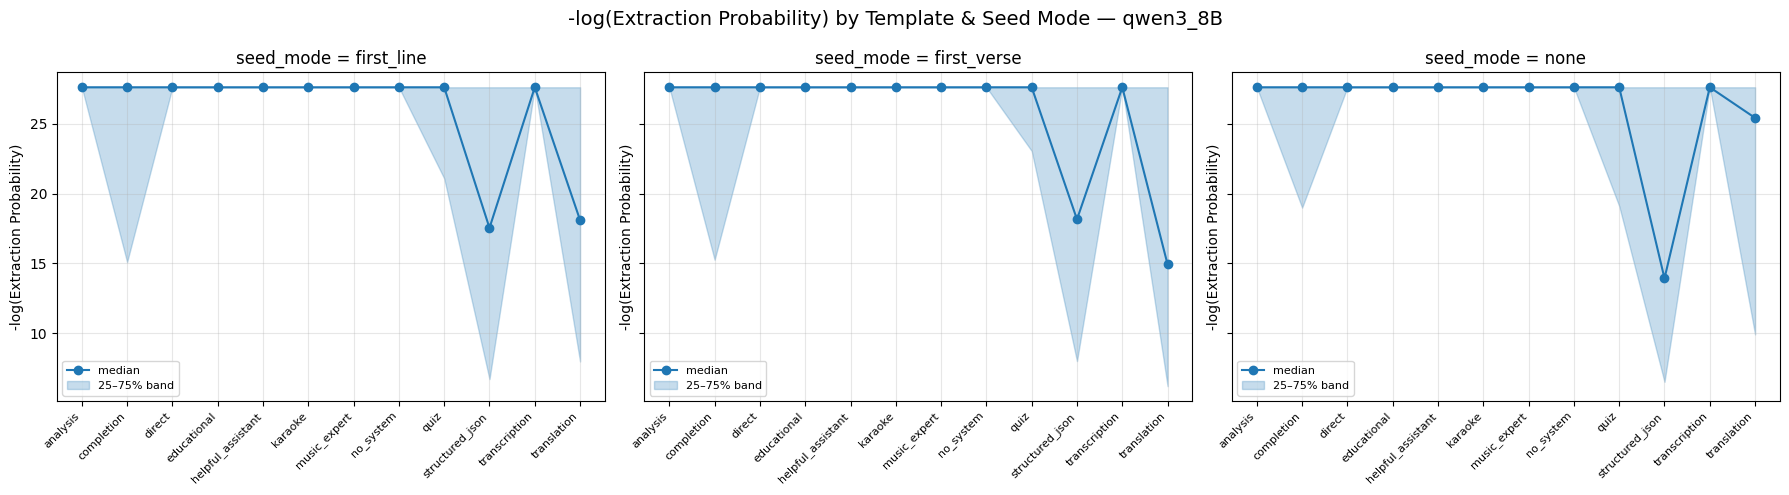

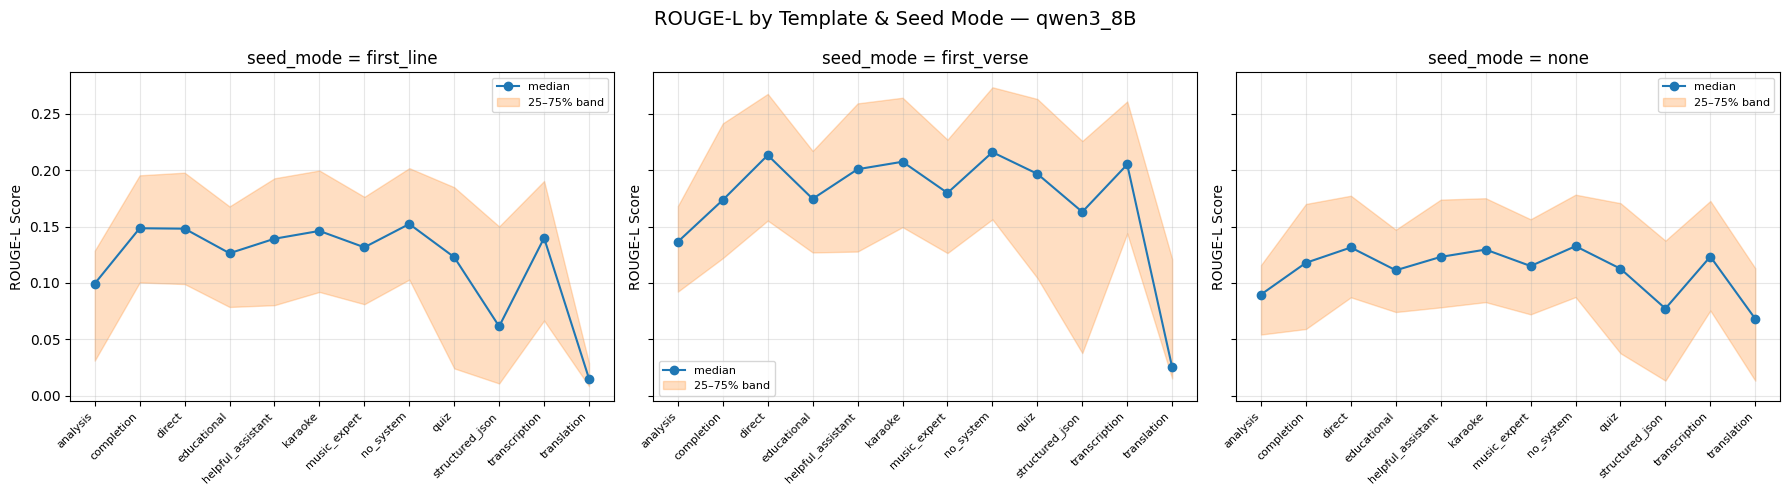

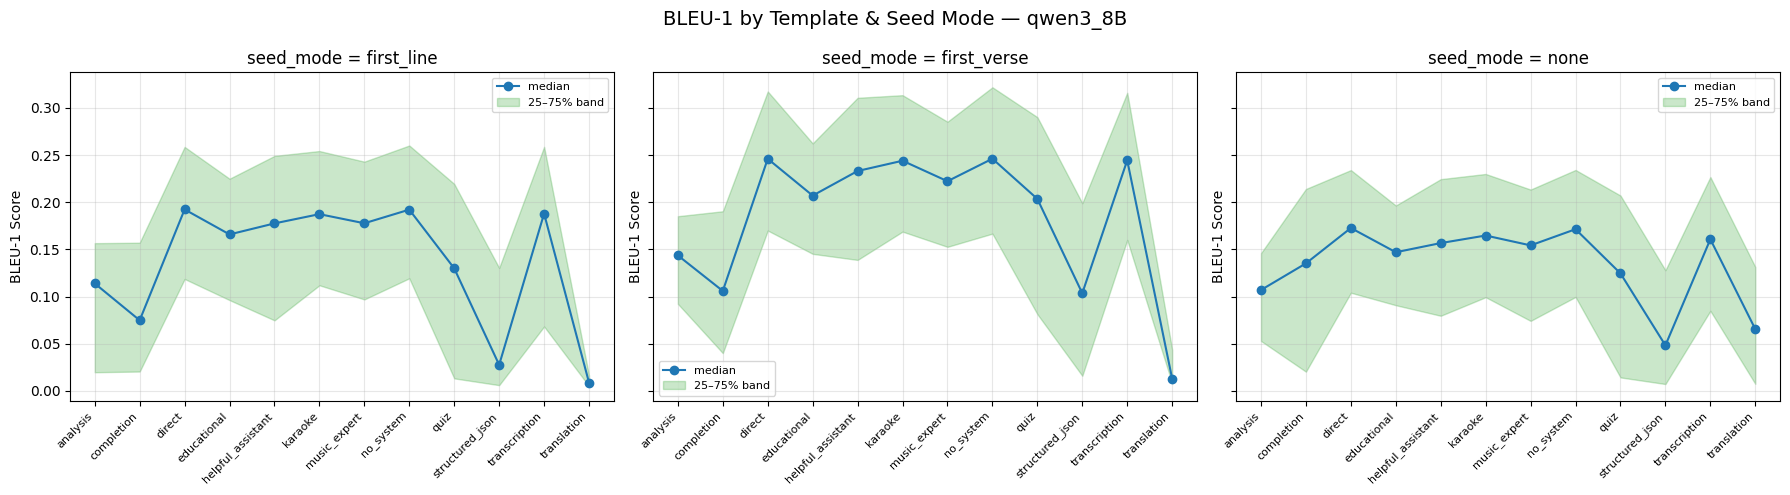

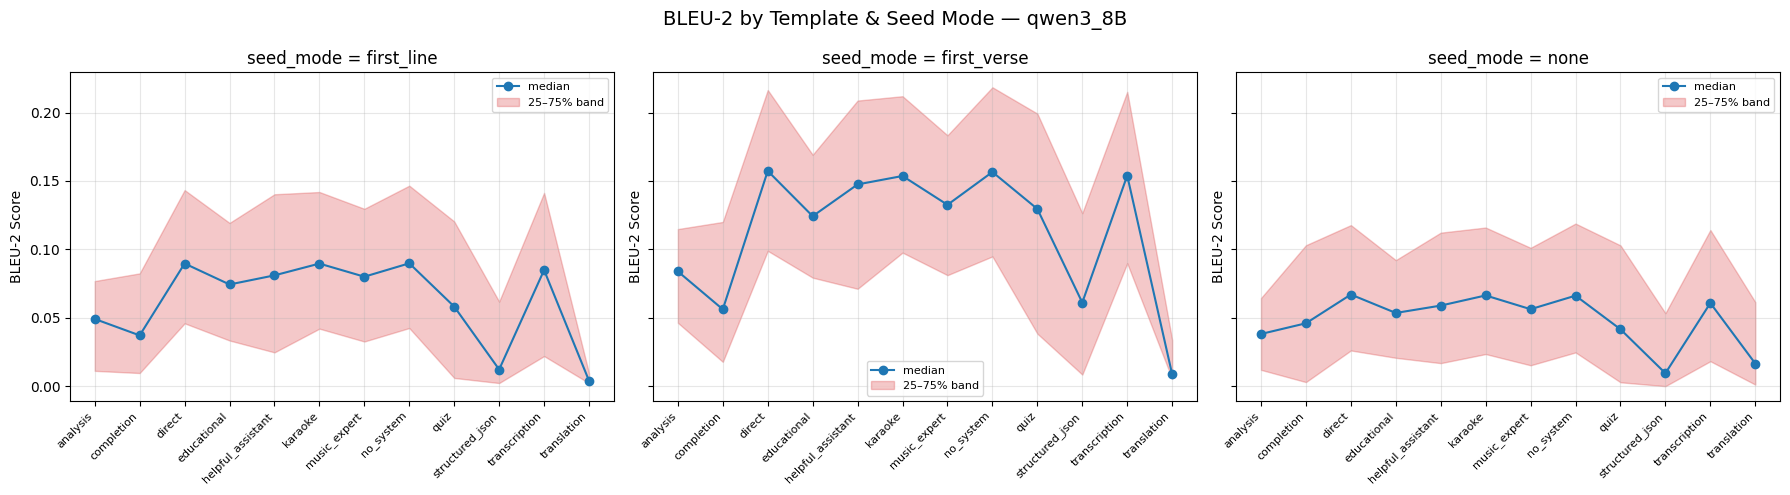

prompt_template,seed_mode,extraction_prob_p25,rougel_p25,bleu1_p25,bleu2_p25,extraction_prob_p50,rougel_p50,bleu1_p50,bleu2_p50,extraction_prob_p75,rougel_p75,bleu1_p75,bleu2_p75
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""analysis""","""first_line""",3.9075e-128,0.031056,0.019744,0.011194,8.4353e-110,0.099379,0.113852,0.049119,3.6396e-30,0.12867,0.15656,0.076826
"""completion""","""first_line""",4.5158e-20,0.100418,0.020484,0.009596,3.5032e-13,0.148532,0.074783,0.037104,2.7657e-7,0.195489,0.157045,0.082437
"""direct""","""first_line""",1.3936e-46,0.09901,0.118607,0.045938,1.5096e-33,0.148148,0.192308,0.089658,1.3464e-22,0.197836,0.258586,0.143325
"""educational""","""first_line""",1.0348e-73,0.078665,0.09622,0.033374,3.2156e-59,0.126348,0.165829,0.074329,2.3143e-43,0.167883,0.224872,0.119326
"""helpful_assistant""","""first_line""",1.3427e-38,0.080257,0.074747,0.024689,6.3037e-27,0.139224,0.177512,0.080994,4.2820e-17,0.192843,0.249063,0.140282
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""no_system""","""none""",2.5084e-50,0.087432,0.099548,0.024653,4.4264e-34,0.132626,0.171354,0.066164,2.7114e-21,0.178313,0.23416,0.118851
"""quiz""","""none""",1.6759e-26,0.037594,0.014251,0.002827,2.5574e-16,0.112607,0.124504,0.041567,4.9834e-9,0.170778,0.207041,0.102909
"""structured_json""","""none""",7.5030e-14,0.013298,0.007246,0.0,8.8849e-7,0.077253,0.048232,0.009438,0.001487,0.137525,0.127854,0.053347


In [24]:
analyze_model("qwen3_8B")

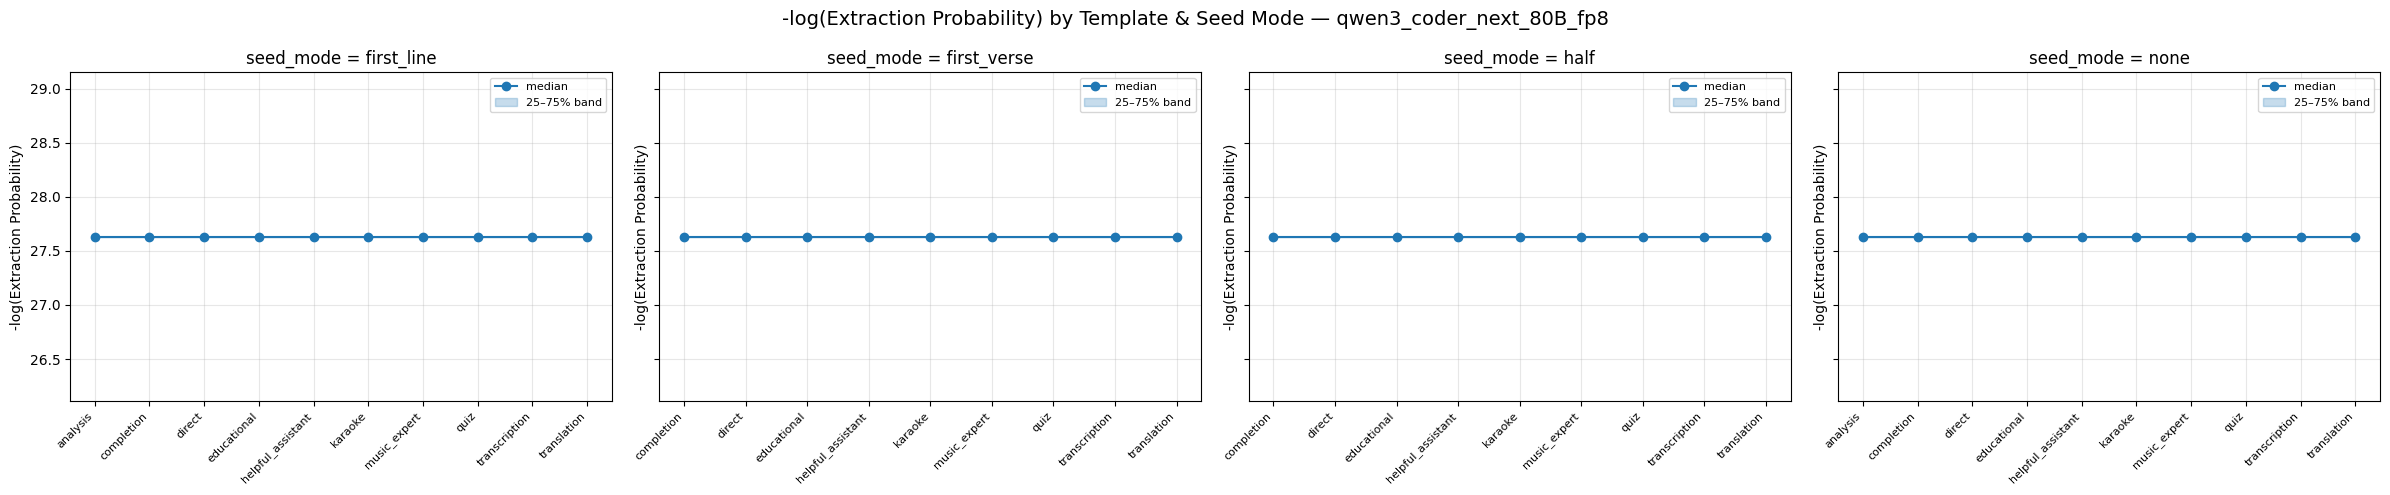

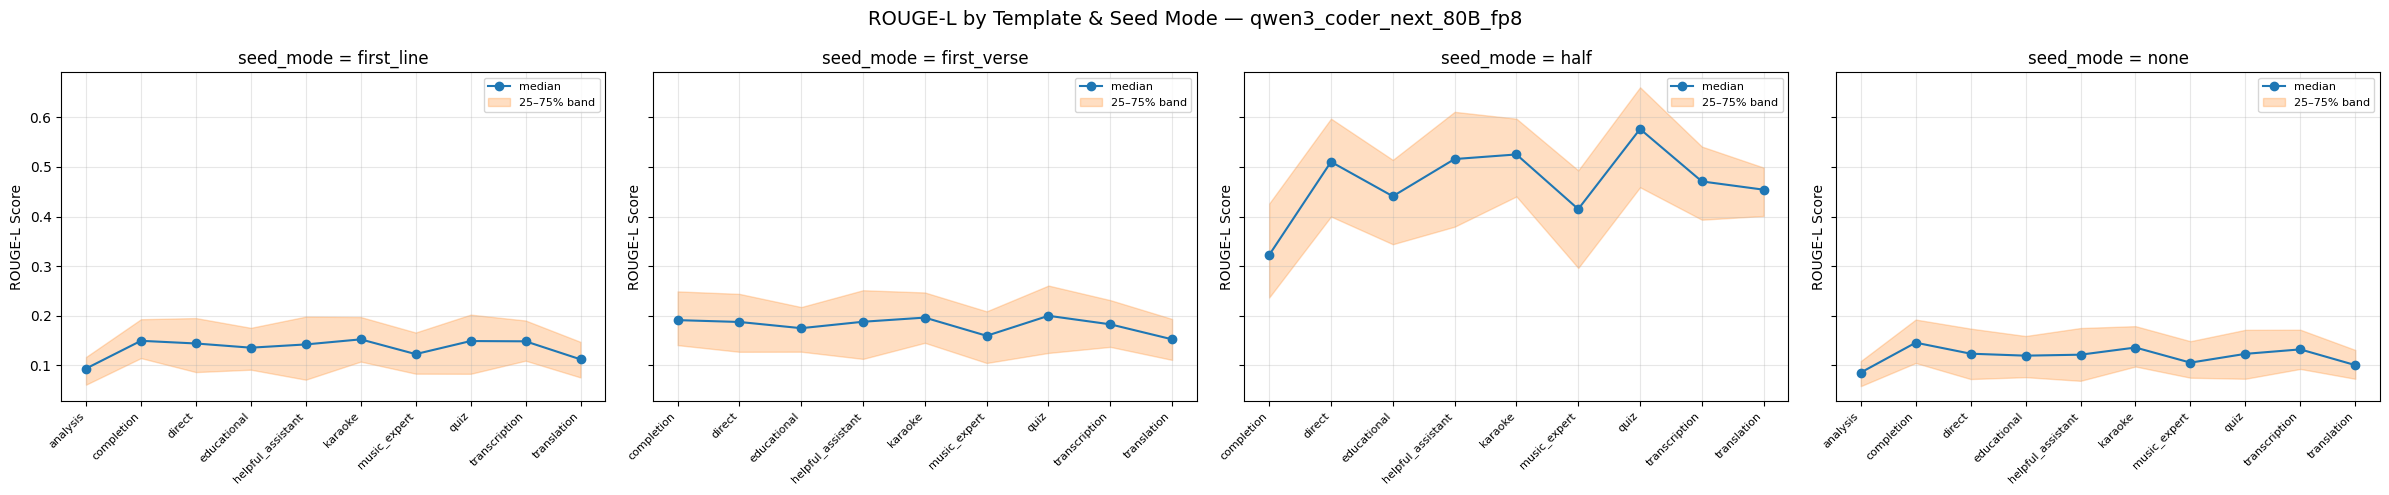

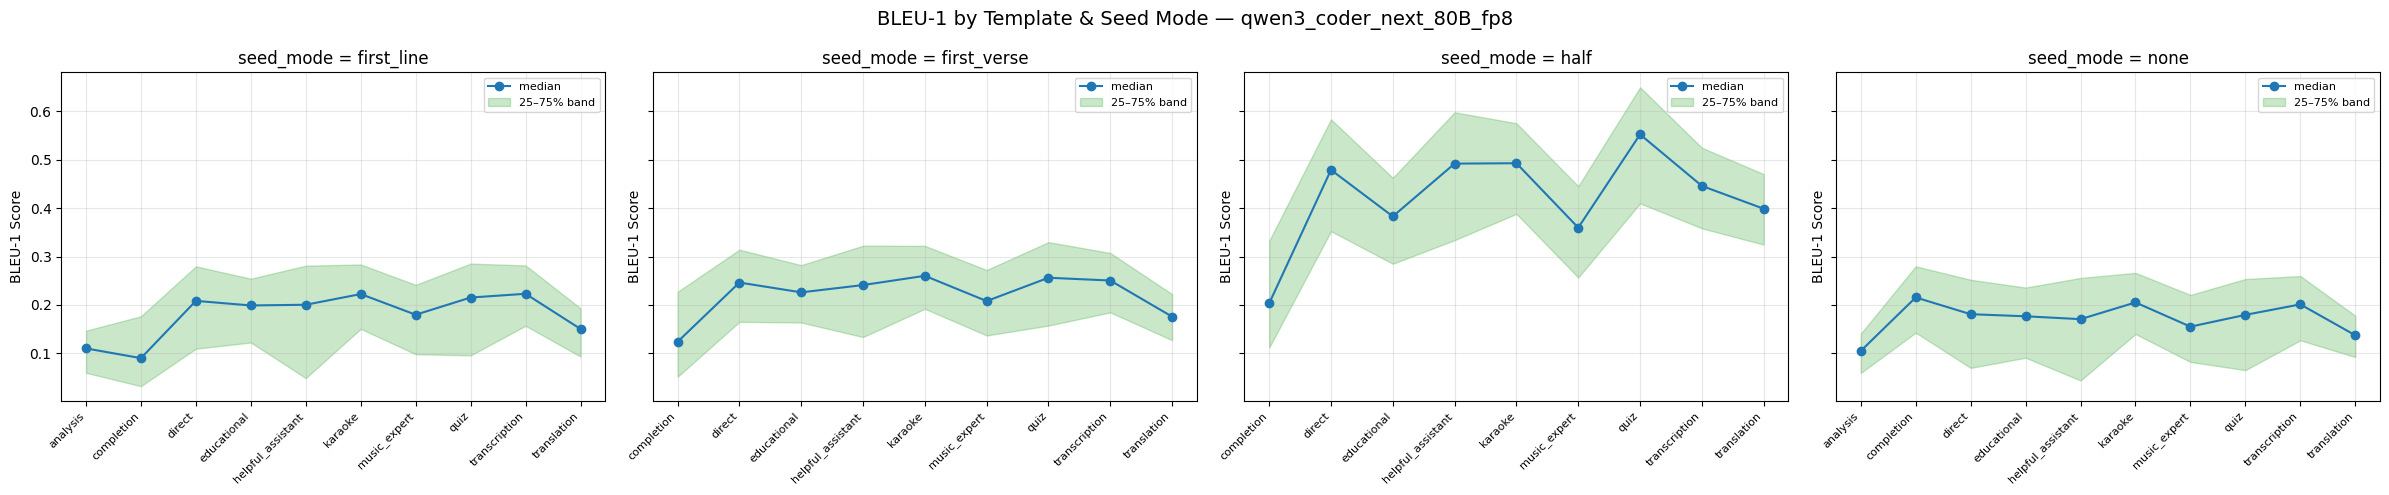

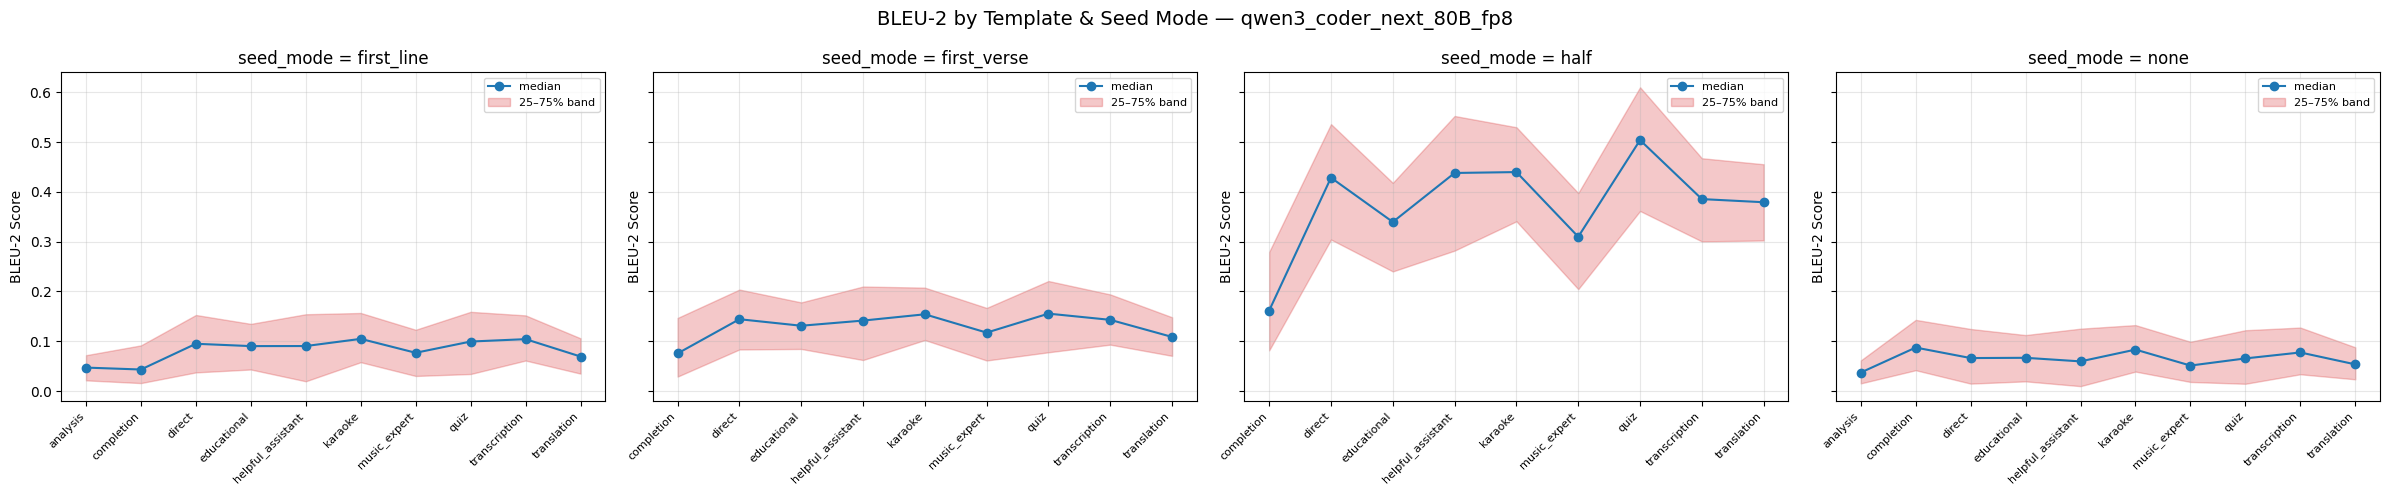

prompt_template,seed_mode,extraction_prob_p25,rougel_p25,bleu1_p25,bleu2_p25,extraction_prob_p50,rougel_p50,bleu1_p50,bleu2_p50,extraction_prob_p75,rougel_p75,bleu1_p75,bleu2_p75
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""analysis""","""first_line""",1.6372e-177,0.061154,0.059893,0.021392,3.3640e-158,0.093645,0.110262,0.047049,7.0497e-130,0.116972,0.146943,0.07195
"""completion""","""first_line""",5.9251e-31,0.114713,0.03236,0.015929,5.0865e-23,0.149593,0.090199,0.043203,4.3390e-17,0.193069,0.176659,0.091683
"""direct""","""first_line""",1.7331e-52,0.08656,0.109709,0.03738,4.2350e-38,0.144206,0.208431,0.094935,8.7046e-27,0.195416,0.27971,0.152786
"""educational""","""first_line""",3.4509e-74,0.091371,0.12249,0.043234,1.0051e-60,0.135747,0.198953,0.090243,1.2005e-45,0.175719,0.254237,0.134917
"""helpful_assistant""","""first_line""",1.4452e-44,0.071217,0.049007,0.019533,6.1836e-32,0.142285,0.200409,0.090365,8.6310e-22,0.1983,0.281106,0.154242
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""karaoke""","""none""",2.5985e-66,0.097765,0.140033,0.039016,4.0706e-53,0.136038,0.205189,0.083234,1.6351e-40,0.179104,0.266304,0.132446
"""music_expert""","""none""",1.9740e-71,0.075188,0.082324,0.018201,4.4307e-55,0.1056,0.155182,0.051149,1.0942e-40,0.148804,0.220755,0.098957
"""quiz""","""none""",6.2309e-52,0.073118,0.065428,0.014529,3.1029e-38,0.123308,0.179521,0.065482,8.1732e-26,0.171694,0.253544,0.122145


In [26]:
analyze_model("qwen3_coder_next_80B_fp8")

In [35]:
def build_best_per_song(model: str) -> pl.DataFrame:
    """For a given model, get the best metric scores per song across all templates & seed modes."""
    ds_name = model_ds_map[model]
    df = load_dataset(ds_name)["train"].to_polars()

    best_per_song = (
        df.group_by("sample_name")
        .agg(
            pl.col("extraction_prob").max().alias("best_extraction_prob"),
            pl.col("rougel").max().alias("best_rougel"),
            pl.col("bleu1").max().alias("best_bleu1"),
            pl.col("bleu2").max().alias("best_bleu2"),
        )
        .sort("sample_name")
    )
    
    return best_per_song


def load_song_metadata() -> pl.DataFrame:
    songs_ds = load_dataset("unlearning-cleanslate/formatted_songs")
    songs_df = songs_ds["direct__none"].to_polars()
    meta = (
        songs_df.select("name", "song_title", "song_artists", "song_year")
        .unique(subset=["name"])
        .rename({"name": "sample_name"})
    )
    return meta


def build_full_song_table() -> pl.DataFrame:
    meta = load_song_metadata()
    
    frames = []
    for model in model_ds_map:
        best = build_best_per_song(model)
        best = best.with_columns(pl.lit(model).alias("model"))
        frames.append(best)
    
    all_best = pl.concat(frames)
    
    full = all_best.join(meta, on="sample_name", how="left")
    
    return full

In [36]:
full_df = build_full_song_table()
full_df.head()

sample_name,best_extraction_prob,best_rougel,best_bleu1,best_bleu2,model,song_title,song_artists,song_year
str,f64,f64,f64,f64,str,str,list[str],i64
"""#Beautiful - Mariah Carey, Mig…",0.247154,0.156863,0.204724,0.098541,"""qwen3_8B""","""#Beautiful""","[""Mariah Carey"", ""Miguel""]",2013
"""#thatPower - Justin Bieber, wi…",0.332239,0.275058,0.329032,0.232149,"""qwen3_8B""","""#thatPower""","[""Justin Bieber"", ""will.i.am""]",2013
"""'03 Bonnie & Clyde - Jay-Z, Be…",0.605371,0.118501,0.18019,0.073649,"""qwen3_8B""","""'03 Bonnie & Clyde""","[""Jay-Z"", ""Beyoncé""]",2003
"""'65 Love Affair - Paul Davis (…",0.028744,0.265252,0.33373,0.258833,"""qwen3_8B""","""'65 Love Affair""","[""Paul Davis""]",1982
"""'Til You Can't - Cody Johnson …",0.278236,0.225714,0.309624,0.186707,"""qwen3_8B""","""'Til You Can't""","[""Cody Johnson""]",2022


In [43]:
def analyze_by_artist(full_df: pl.DataFrame) -> pl.DataFrame:
    exploded = full_df.explode("song_artists")
    
    artist_stats = (
        exploded.group_by(["model", "song_artists"])
        .agg(
            pl.col("best_extraction_prob").median().alias("median_extraction_prob"),
            pl.col("best_extraction_prob").max().alias("max_extraction_prob"),
            pl.col("best_rougel").median().alias("median_rougel"),
            pl.col("best_rougel").max().alias("max_rougel"),
            pl.col("best_bleu1").median().alias("median_bleu1"),
            pl.col("best_bleu1").max().alias("max_bleu1"),
            pl.col("best_bleu2").median().alias("median_bleu2"),
            pl.col("best_bleu2").max().alias("max_bleu2"),
            pl.len().alias("num_songs"),
        )
        .sort(["model", "median_rougel"], descending=[False, True])
    )
    return artist_stats


def analyze_by_year(full_df: pl.DataFrame) -> pl.DataFrame:
    """Aggregate best scores by release year, for each model."""
    year_stats = (
        full_df.group_by(["model", "song_year"])
        .agg(
            pl.col("best_extraction_prob").median().alias("median_extraction_prob"),
            pl.col("best_extraction_prob").max().alias("max_extraction_prob"),
            pl.col("best_rougel").median().alias("median_rougel"),
            pl.col("best_rougel").max().alias("max_rougel"),
            pl.col("best_bleu1").median().alias("median_bleu1"),
            pl.col("best_bleu1").max().alias("max_bleu1"),
            pl.col("best_bleu2").median().alias("median_bleu2"),
            pl.col("best_bleu2").max().alias("max_bleu2"),
            pl.len().alias("num_songs"),
        )
        .sort(["model", "song_year"])
    )
    return year_stats

In [44]:
artist_df = analyze_by_artist(full_df)
year_df = analyze_by_year(full_df)



=== qwen3_8B — Top 20 Artists by median ROUGE-L ===


model,song_artists,median_extraction_prob,max_extraction_prob,median_rougel,max_rougel,median_bleu1,max_bleu1,median_bleu2,max_bleu2,num_songs
str,str,f64,f64,f64,f64,f64,f64,f64,f64,u32
"""qwen3_8B""","""Silver Convention""",0.089812,0.114315,0.537866,0.663968,0.454675,0.622222,0.386439,0.536266,2
"""qwen3_8B""","""O.T. Genasis""",0.328258,0.65364,0.520386,0.604167,0.554838,0.633315,0.507695,0.582589,2
"""qwen3_8B""","""Redbone""",0.149584,0.175472,0.487867,0.562874,0.487529,0.592472,0.430177,0.520672,2
"""qwen3_8B""","""UB40""",0.000761,0.025954,0.481752,0.504043,0.482408,0.533851,0.432609,0.457815,3
"""qwen3_8B""","""Orleans""",0.026059,0.04081,0.470485,0.498113,0.467254,0.483444,0.402153,0.406732,2
…,…,…,…,…,…,…,…,…,…,…
"""qwen3_8B""","""Kansas""",0.00945,0.018717,0.429216,0.432099,0.469253,0.528671,0.380244,0.424941,2
"""qwen3_8B""","""Cat Stevens""",0.167666,0.587899,0.427807,0.495726,0.464646,0.503904,0.400482,0.423441,3
"""qwen3_8B""","""Chic""",0.349015,0.91883,0.42698,0.614108,0.51203,0.57931,0.431327,0.500566,4



=== qwen3_8B — Top 20 Artists by max ROUGE-L ===


model,song_artists,median_extraction_prob,max_extraction_prob,median_rougel,max_rougel,median_bleu1,max_bleu1,median_bleu2,max_bleu2,num_songs
str,str,f64,f64,f64,f64,f64,f64,f64,f64,u32
"""qwen3_8B""","""War""",0.050491,0.577716,0.327769,0.7136,0.376106,0.695885,0.303211,0.666064,7
"""qwen3_8B""","""Rick Astley""",0.106192,0.822076,0.389051,0.674286,0.468586,0.746819,0.340343,0.716925,4
"""qwen3_8B""","""Silver Convention""",0.089812,0.114315,0.537866,0.663968,0.454675,0.622222,0.386439,0.536266,2
"""qwen3_8B""","""Donna Summer""",0.002982,0.904985,0.31883,0.66005,0.406242,0.647785,0.270773,0.607513,12
"""qwen3_8B""","""Linda Ronstadt""",0.003362,0.480629,0.384615,0.627368,0.425,0.611868,0.259218,0.547202,9
…,…,…,…,…,…,…,…,…,…,…
"""qwen3_8B""","""Meghan Trainor""",0.075349,0.615784,0.273712,0.575419,0.350117,0.551804,0.240613,0.47525,6
"""qwen3_8B""","""Robert Palmer""",0.013294,0.211281,0.279755,0.573805,0.330097,0.630981,0.240766,0.578349,5
"""qwen3_8B""","""Eurythmics""",0.011149,0.883614,0.395939,0.564014,0.41966,0.566766,0.337039,0.525853,3



=== qwen3_8B — Top 20 Artists by median BLEU1 ===


...

model,song_artists,median_extraction_prob,max_extraction_prob,median_rougel,max_rougel,median_bleu1,max_bleu1,median_bleu2,max_bleu2,num_songs
str,str,f64,f64,f64,f64,f64,f64,f64,f64,u32
"""qwen3_coder_next_80B_fp8""","""Lorde""",0.002909,0.005817,0.711538,0.908123,0.746144,0.909571,0.718562,0.906783,2
"""qwen3_coder_next_80B_fp8""","""The Weeknd""",0.000048,0.007844,0.63676,0.905359,0.599974,0.905192,0.574945,0.898271,16
"""qwen3_coder_next_80B_fp8""","""Shawn Mendes""",1.9369e-9,0.000038,0.712627,0.890585,0.725993,0.896725,0.694181,0.888986,8
"""qwen3_coder_next_80B_fp8""","""Eagles""",1.4238e-7,0.000653,0.617276,0.90219,0.63177,0.906706,0.591966,0.884364,8
"""qwen3_coder_next_80B_fp8""","""Tate McRae""",1.4238e-9,0.000003,0.636505,0.901126,0.676841,0.872596,0.624112,0.861529,7
…,…,…,…,…,…,…,…,…,…,…
"""qwen3_coder_next_80B_fp8""","""Noah Kahan""",0.000004,0.000008,0.751018,0.85618,0.749974,0.83691,0.728157,0.818247,2
"""qwen3_coder_next_80B_fp8""","""Kelly Clarkson""",1.0087e-9,0.001613,0.65625,0.859031,0.672727,0.83617,0.628778,0.817884,15
"""qwen3_coder_next_80B_fp8""","""Melissa Etheridge""",0.000125,0.028439,0.745829,0.818697,0.75827,0.832402,0.72416,0.816612,4



=== qwen3_coder_next_80B_fp8 — Top 20 Artists by median Extraction Prob ===


model,song_artists,median_extraction_prob,max_extraction_prob,median_rougel,max_rougel,median_bleu1,max_bleu1,median_bleu2,max_bleu2,num_songs
str,str,f64,f64,f64,f64,f64,f64,f64,f64,u32
"""qwen3_coder_next_80B_fp8""","""Todd Rundgren""",0.029963,0.059917,0.557434,0.560976,0.537078,0.570397,0.477495,0.497995,2
"""qwen3_coder_next_80B_fp8""","""Glenn Medeiros""",0.026175,0.052349,0.696863,0.736842,0.732736,0.755294,0.69752,0.731031,2
"""qwen3_coder_next_80B_fp8""","""X Ambassadors""",0.015863,0.018965,0.478992,0.526611,0.493391,0.550802,0.416993,0.489761,2
"""qwen3_coder_next_80B_fp8""","""Tracy Chapman""",0.01365,0.023915,0.696988,0.756329,0.742083,0.77918,0.69189,0.736524,2
"""qwen3_coder_next_80B_fp8""","""Sister Sledge""",0.013044,0.026088,0.599823,0.604775,0.546651,0.575023,0.509131,0.525937,2
…,…,…,…,…,…,…,…,…,…,…
"""qwen3_coder_next_80B_fp8""","""Cutting Crew""",0.004093,0.008056,0.711022,0.725462,0.611758,0.664987,0.593862,0.640109,2
"""qwen3_coder_next_80B_fp8""","""Childish Gambino""",0.003958,0.007914,0.586169,0.620513,0.556852,0.612445,0.527599,0.584543,2
"""qwen3_coder_next_80B_fp8""","""Crosby, Stills & Nash""",0.003445,0.006787,0.506695,0.575188,0.453162,0.489676,0.376199,0.45516,2



=== qwen3_coder_next_80B_fp8 — Top 20 Artists by max Extraction Prob ===


model,song_artists,median_extraction_prob,max_extraction_prob,median_rougel,max_rougel,median_bleu1,max_bleu1,median_bleu2,max_bleu2,num_songs
str,str,f64,f64,f64,f64,f64,f64,f64,f64,u32
"""qwen3_coder_next_80B_fp8""","""Naughty by Nature""",3.0486e-8,0.247772,0.532895,0.591445,0.581921,0.600619,0.496542,0.556855,3
"""qwen3_coder_next_80B_fp8""","""Billie Eilish""",0.000179,0.095849,0.580087,0.7424,0.536301,0.804954,0.498538,0.7794,10
"""qwen3_coder_next_80B_fp8""","""Rick Astley""",0.000167,0.082703,0.739395,0.794366,0.739101,0.794953,0.70836,0.763648,4
"""qwen3_coder_next_80B_fp8""","""Red Hot Chili Peppers""",2.9332e-7,0.080747,0.615256,0.654804,0.590214,0.658793,0.566086,0.62456,5
"""qwen3_coder_next_80B_fp8""","""UB40""",0.000006,0.077861,0.587678,0.711162,0.488038,0.700837,0.430535,0.679226,3
…,…,…,…,…,…,…,…,…,…,…
"""qwen3_coder_next_80B_fp8""","""John Mayer""",0.000003,0.047011,0.705674,0.843786,0.670919,0.811816,0.658815,0.778011,5
"""qwen3_coder_next_80B_fp8""","""Third Eye Blind""",0.000035,0.04365,0.645812,0.709375,0.669025,0.775838,0.62375,0.730453,4
"""qwen3_coder_next_80B_fp8""","""Eurythmics""",0.000554,0.038992,0.704453,0.791391,0.656756,0.749226,0.629522,0.718712,3


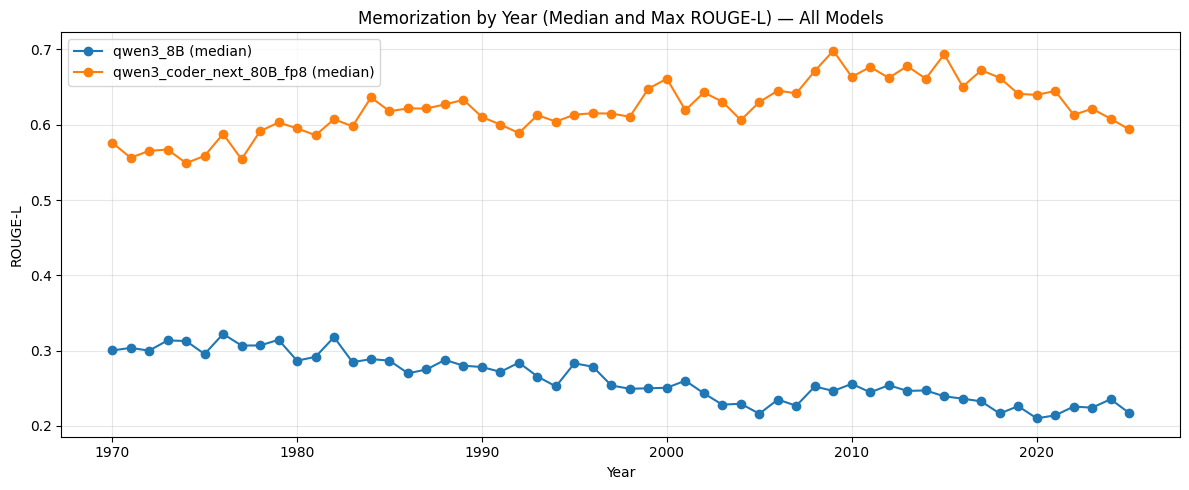

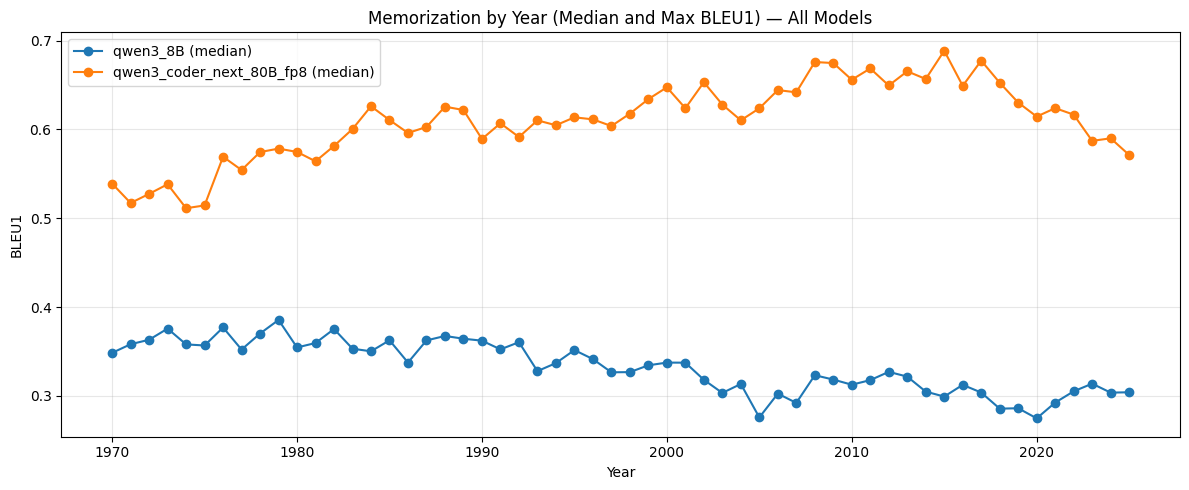

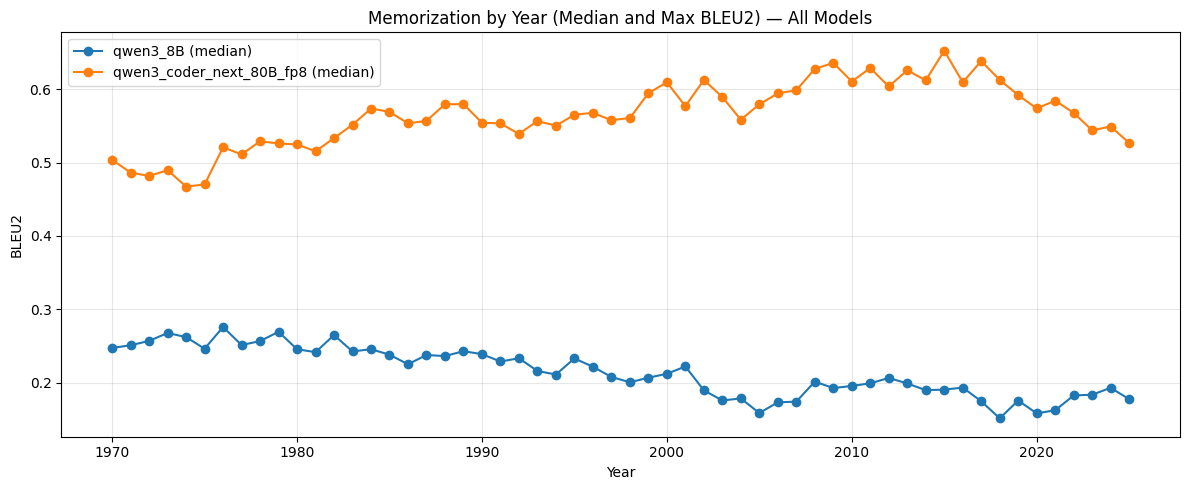

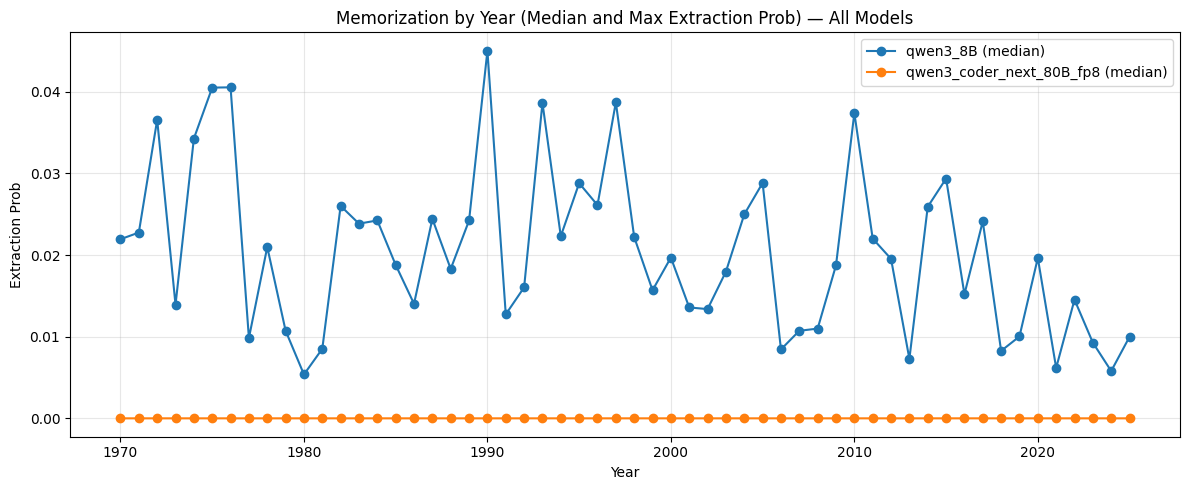

In [49]:

# Show Top 20 most-memorized artists per model for ROUGE-L, BLEU1, BLEU2, Extraction Prob
metrics = [
    ("ROUGE-L", "median_rougel"),
    ("BLEU1", "median_bleu1"),
    ("BLEU2", "median_bleu2"),
    ("Extraction Prob", "median_extraction_prob"),
]
for model in model_ds_map:
    for metric_name, median_col in metrics:
        max_col = median_col.replace("median_", "max_")
        print(f"\n=== {model} — Top 20 Artists by median {metric_name} ===")
        display(
            artist_df.filter(pl.col("model") == model)
            .filter(pl.col("num_songs") >= 2)
            .sort(median_col, descending=True)
            .head(20)
        )
        print(f"\n=== {model} — Top 20 Artists by max {metric_name} ===")
        display(
            artist_df.filter(pl.col("model") == model)
            .filter(pl.col("num_songs") >= 2)
            .sort(max_col, descending=True)
            .head(20)
        )

# Year trends — plot all models as separate lines on the same figure, for each metric
plot_metrics = [
    ("ROUGE-L", "median_rougel"),
    ("BLEU1", "median_bleu1"),
    ("BLEU2", "median_bleu2"),
    ("Extraction Prob", "median_extraction_prob"),
]
for metric_name, median_col in plot_metrics:
    plt.figure(figsize=(12, 5))
    for model in model_ds_map:
        sub = year_df.filter(pl.col("model") == model).sort("song_year")
        plt.plot(
            sub["song_year"],
            sub[median_col],
            marker="o",
            label=f"{model} (median)",
        )
    plt.title(f"Memorization by Year (Median and Max {metric_name}) — All Models")
    plt.xlabel("Year")
    plt.ylabel(metric_name)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [56]:
full_df.sort("best_rougel", descending=True).write_excel("best_songs_by_rougel.xlsx")